# EDA, Clean และ Data Prep: น้ำท่วมรายเดือน (2020–2025)

ลำดับการทำงาน: โหลดข้อมูล → EDA/กราฟก่อน Clean → Clean → Data Prep → EDA/กราฟหลังเตรียมข้อมูล → Save CSV

## 1. โหลดข้อมูลต้นฉบับ

อ่านไฟล์ `NST_amphoe_monthly_flood_2020_2025.csv` จาก `raw_data` และเลือกเฉพาะปี 2020–2025 เก็บข้อมูลก่อน Clean ไว้ใน `raw_data` สำหรับ EDA รอบแรก

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

filename = 'NST_amphoe_monthly_flood_2020_2025.csv'
root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'raw_data' / filename).is_file()), None)
if root is None:
    raise FileNotFoundError(f'ไม่พบไฟล์ raw_data/{filename}')

source_path = root / 'raw_data' / filename
years = [2020, 2021, 2022, 2023, 2024, 2025]
all_data = pd.read_csv(source_path)
raw_data = all_data.loc[all_data['year'].isin(years)].copy()

print(f'ไฟล์ต้นทาง: {source_path}')
print(f'ข้อมูลทั้งหมดในไฟล์: {len(all_data):,} แถว | หลังเลือกปี {years}: {len(raw_data):,} แถว')
print(f'จำนวนอำเภอ: {raw_data["amphoe"].nunique()}')
display(raw_data.head())

ไฟล์ต้นทาง: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\raw_data\NST_amphoe_monthly_flood_2020_2025.csv
ข้อมูลทั้งหมดในไฟล์: 1,296 แถว | หลังเลือกปี [2020, 2021, 2022, 2023, 2024, 2025]: 1,296 แถว
จำนวนอำเภอ: 18


,province,amphoe,year,month,month_th,flooded,flood_status,flood_events_month,flood_windows,max_flood_ha,flood_events_year
0,นครศรีธรรมราช,Bang Khan,2020,1,มกราคม,0,ไม่ท่วม,0.0,0.0,0.000,0.0
1,นครศรีธรรมราช,Bang Khan,2020,2,กุมภาพันธ์,0,ไม่ท่วม,0.0,0.0,0.000,0.0
2,นครศรีธรรมราช,Bang Khan,2020,3,มีนาคม,0,ไม่ท่วม,0.0,0.0,0.000,0.0
3,นครศรีธรรมราช,Bang Khan,2020,4,เมษายน,0,ไม่ท่วม,0.0,0.0,0.000,0.0
4,นครศรีธรรมราช,Bang Khan,2020,5,พฤษภาคม,0,ไม่ท่วม,0.0,0.0,0.246,0.0


## 2. EDA ก่อน Clean: ตรวจข้อมูลและแสดงกราฟ

สำรวจ `raw_data` ก่อนทำความสะอาด กราฟแสดงจำนวนอำเภอที่น้ำท่วมและพื้นที่น้ำท่วมสูงสุดรายเดือน ส่วนจำนวนเหตุการณ์รายปีนับ `flood_events_year` เพียงครั้งเดียวต่ออำเภอ-ปี เพราะค่าเดียวกันซ้ำอยู่ในทุกเดือน

ขนาดข้อมูล: (1296, 11)
ค่าว่างต่อคอลัมน์:
 province              0
amphoe                0
year                  0
month                 0
month_th              0
flooded               0
flood_status          0
flood_events_month    0
flood_windows         0
max_flood_ha          0
flood_events_year     0
แถวซ้ำทั้งหมด: 0
แถวซ้ำตามอำเภอ-ปี-เดือน: 0


,flooded,flood_events_month,flood_windows,max_flood_ha,flood_events_year
count,1296.00,1296.00,1296.00,1296.00,1296.00
mean,0.59,0.15,1.32,39.18,1.81
std,0.49,0.36,1.23,83.58,2.14
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,1.23,0.00
50%,1.00,0.00,1.00,7.78,1.00
75%,1.00,0.00,2.00,32.88,3.00
max,1.00,2.00,3.00,685.69,8.00


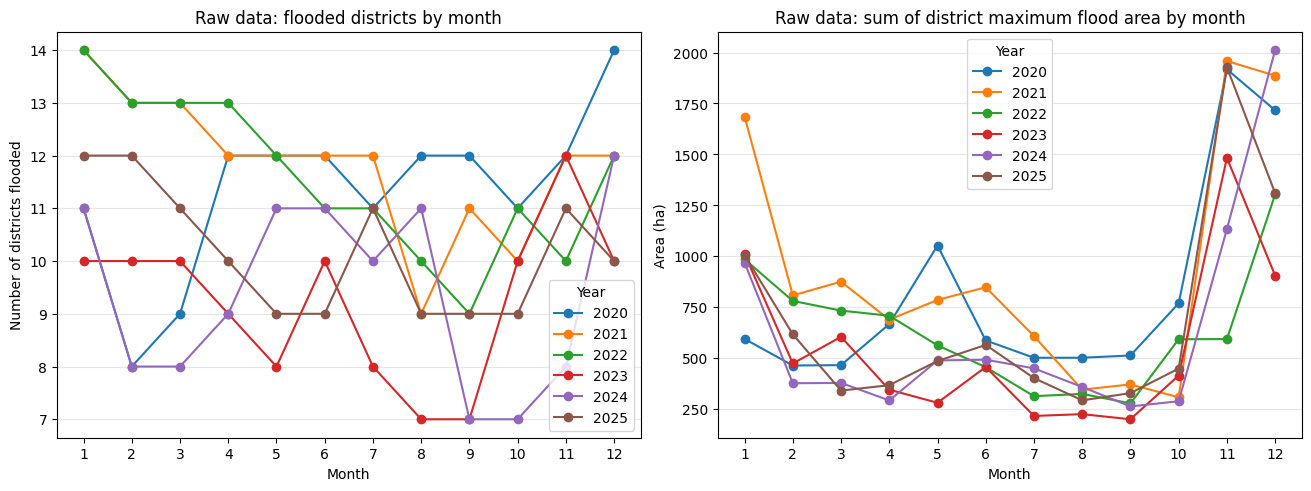

,year,month,flooded_districts,max_flood_area_sum_ha,flood_events
0,2020,1,11,594.44,11.0
1,2020,2,8,464.13,1.0
2,2020,3,9,465.98,2.0
3,2020,4,12,667.35,5.0
4,2020,5,12,1053.04,0.0
5,2020,6,12,587.15,0.0
6,2020,7,11,502.10,2.0
7,2020,8,12,502.26,1.0
8,2020,9,12,513.33,1.0
9,2020,10,11,769.40,1.0


In [2]:
print('ขนาดข้อมูล:', raw_data.shape)
print('ค่าว่างต่อคอลัมน์:\n', raw_data.isna().sum().to_string())
print('แถวซ้ำทั้งหมด:', int(raw_data.duplicated().sum()))
print('แถวซ้ำตามอำเภอ-ปี-เดือน:', int(raw_data.duplicated(['amphoe', 'year', 'month']).sum()))
display(raw_data[['flooded', 'flood_events_month', 'flood_windows', 'max_flood_ha', 'flood_events_year']].describe().round(2))

raw_monthly = raw_data.groupby(['year', 'month'], as_index=False).agg(
    flooded_districts=('flooded', 'sum'),
    max_flood_area_sum_ha=('max_flood_ha', 'sum'),
    flood_events=('flood_events_month', 'sum'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for year in years:
    subset = raw_monthly.loc[raw_monthly['year'] == year]
    axes[0].plot(subset['month'], subset['flooded_districts'], marker='o', label=str(year))
    axes[1].plot(subset['month'], subset['max_flood_area_sum_ha'], marker='o', label=str(year))
axes[0].set(title='Raw data: flooded districts by month', xlabel='Month', ylabel='Number of districts flooded', xticks=range(1, 13))
axes[1].set(title='Raw data: sum of district maximum flood area by month', xlabel='Month', ylabel='Area (ha)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)
display(raw_monthly.head(12).round(2))

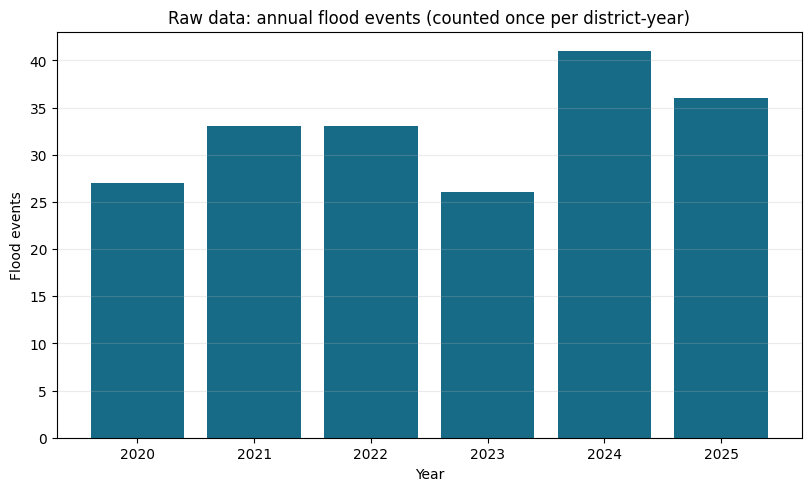

,year,flooded_districts,flood_events
0,2020,14,27.0
1,2021,10,33.0
2,2022,8,33.0
3,2023,9,26.0
4,2024,13,41.0
5,2025,8,36.0


In [3]:
raw_annual_district = raw_data[['province', 'amphoe', 'year', 'flood_events_year']].drop_duplicates(
    ['amphoe', 'year']
)
raw_annual = raw_annual_district.groupby('year', as_index=False).agg(
    flooded_districts=('flood_events_year', lambda values: int((values > 0).sum())),
    flood_events=('flood_events_year', 'sum'),
)
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
ax.bar(raw_annual['year'].astype(str), raw_annual['flood_events'], color='#176B87')
ax.set(title='Raw data: annual flood events (counted once per district-year)', xlabel='Year', ylabel='Flood events')
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)
display(raw_annual)

## 3. Clean ข้อมูล

จัดช่องว่างชื่อจังหวัดและอำเภอ แปลงชนิดข้อมูล ลบแถวซ้ำ ตรวจค่าว่างและค่าที่อยู่นอกช่วงที่ควรเป็น เช่น เดือนและตัวบ่งชี้น้ำท่วม โดยคงค่าศูนย์ไว้ตามข้อมูลจริง

In [4]:
clean_data = raw_data.copy()
for column in ['province', 'amphoe', 'month_th', 'flood_status']:
    clean_data[column] = clean_data[column].astype('string').str.strip()
clean_data['amphoe'] = clean_data['amphoe'].str.replace(r'\s+', ' ', regex=True)

integer_columns = ['year', 'month', 'flooded', 'flood_events_month', 'flood_windows', 'flood_events_year']
numeric_columns = ['max_flood_ha']
for column in integer_columns + numeric_columns:
    clean_data[column] = pd.to_numeric(clean_data[column], errors='coerce')

rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates(subset=['amphoe', 'year', 'month']).copy()
print(f'ลบแถวอำเภอ-ปี-เดือนซ้ำ: {rows_before - len(clean_data)} แถว')

required_columns = ['province', 'amphoe', 'year', 'month', 'flooded', 'flood_status',
                    'flood_events_month', 'flood_windows', 'max_flood_ha', 'flood_events_year']
invalid_required = clean_data[required_columns].isna().any(axis=1)
if invalid_required.any():
    print(f'ลบแถวที่ข้อมูลสำคัญขาดหาย/ไม่ใช่ตัวเลข: {int(invalid_required.sum())} แถว')
    clean_data = clean_data.loc[~invalid_required].copy()
else:
    print('ไม่พบข้อมูลสำคัญที่ขาดหายหรือไม่ใช่ตัวเลข')

if not clean_data['year'].isin(years).all() or not clean_data['month'].between(1, 12).all():
    raise ValueError('พบปีหรือเดือนนอกช่วงที่คาดไว้')
if not clean_data['flooded'].isin([0, 1]).all():
    raise ValueError('พบค่า flooded ที่ไม่ใช่ 0 หรือ 1')
count_columns = ['flooded', 'flood_events_month', 'flood_windows', 'flood_events_year']
if (clean_data[count_columns] < 0).any().any() or (clean_data['max_flood_ha'] < 0).any():
    raise ValueError('พบจำนวนเหตุการณ์หรือพื้นที่น้ำท่วมติดลบ')
if clean_data[['province', 'amphoe', 'flood_status']].eq('').any().any():
    raise ValueError('พบชื่อจังหวัด อำเภอ หรือสถานะน้ำท่วมว่าง')

clean_data['year'] = clean_data['year'].astype('int64')
clean_data['month'] = clean_data['month'].astype('int64')
for column in count_columns:
    clean_data[column] = clean_data[column].astype('int64')
print(f'Clean เสร็จ: {len(clean_data)} แถว | {clean_data["amphoe"].nunique()} อำเภอ')

ลบแถวอำเภอ-ปี-เดือนซ้ำ: 0 แถว
ไม่พบข้อมูลสำคัญที่ขาดหายหรือไม่ใช่ตัวเลข
Clean เสร็จ: 1296 แถว | 18 อำเภอ


## 4. Data Prep

เตรียมตารางวิเคราะห์แยกจาก Clean: สร้างวันที่เริ่มเดือน จัดลำดับคอลัมน์และเรียงตามอำเภอ/วันที่ โดยคงคอลัมน์จากข้อมูลเดิมไว้ และตรวจความซ้ำของอำเภอ-เดือน

In [5]:
data_prep = clean_data.copy()
data_prep['month_start'] = pd.to_datetime(
    dict(year=data_prep['year'], month=data_prep['month'], day=1),
    errors='raise',
)
prepared_columns = [
    'province', 'amphoe', 'year', 'month', 'month_start', 'month_th',
    'flooded', 'flood_status', 'flood_events_month', 'flood_windows',
    'max_flood_ha', 'flood_events_year',
]
data_prep = data_prep[prepared_columns].sort_values(
    ['amphoe', 'year', 'month']
).reset_index(drop=True)

if not data_prep['year'].isin(years).all():
    raise ValueError('พบปีนอกช่วงที่ร้องขอ')
if data_prep.duplicated(['amphoe', 'year', 'month']).any():
    raise ValueError('พบข้อมูลซ้ำของอำเภอ-ปี-เดือนใน Data Prep')
if data_prep.isna().any().any():
    raise ValueError('พบค่าว่างในตาราง Data Prep')

print('ขนาดตาราง Data Prep:', data_prep.shape)
print('ปี:', sorted(data_prep['year'].unique().tolist()))
print('จำนวนอำเภอ:', data_prep['amphoe'].nunique())
display(data_prep.head(12))

ขนาดตาราง Data Prep: (1296, 12)
ปี: [2020, 2021, 2022, 2023, 2024, 2025]
จำนวนอำเภอ: 18


,province,amphoe,year,month,month_start,month_th,flooded,flood_status,flood_events_month,flood_windows,max_flood_ha,flood_events_year
0,นครศรีธรรมราช,Bang Khan,2020,1,2020-01-01,มกราคม,0,ไม่ท่วม,0,0,0.000000,0
1,นครศรีธรรมราช,Bang Khan,2020,2,2020-02-01,กุมภาพันธ์,0,ไม่ท่วม,0,0,0.000000,0
2,นครศรีธรรมราช,Bang Khan,2020,3,2020-03-01,มีนาคม,0,ไม่ท่วม,0,0,0.000000,0
3,นครศรีธรรมราช,Bang Khan,2020,4,2020-04-01,เมษายน,0,ไม่ท่วม,0,0,0.000000,0
4,นครศรีธรรมราช,Bang Khan,2020,5,2020-05-01,พฤษภาคม,0,ไม่ท่วม,0,0,0.246000,0
5,นครศรีธรรมราช,Bang Khan,2020,6,2020-06-01,มิถุนายน,0,ไม่ท่วม,0,0,0.491923,0
6,นครศรีธรรมราช,Bang Khan,2020,7,2020-07-01,กรกฎาคม,0,ไม่ท่วม,0,0,0.738001,0
7,นครศรีธรรมราช,Bang Khan,2020,8,2020-08-01,สิงหาคม,0,ไม่ท่วม,0,0,0.491982,0
8,นครศรีธรรมราช,Bang Khan,2020,9,2020-09-01,กันยายน,0,ไม่ท่วม,0,0,0.491992,0
9,นครศรีธรรมราช,Bang Khan,2020,10,2020-10-01,ตุลาคม,0,ไม่ท่วม,0,0,0.492051,0


## 5. EDA หลัง Clean และ Data Prep

แสดงกราฟจำนวนอำเภอที่น้ำท่วม พื้นที่น้ำท่วมสูงสุดรายเดือน และจำนวนเหตุการณ์รายปีจาก `data_prep` หลัง Clean/Data Prep

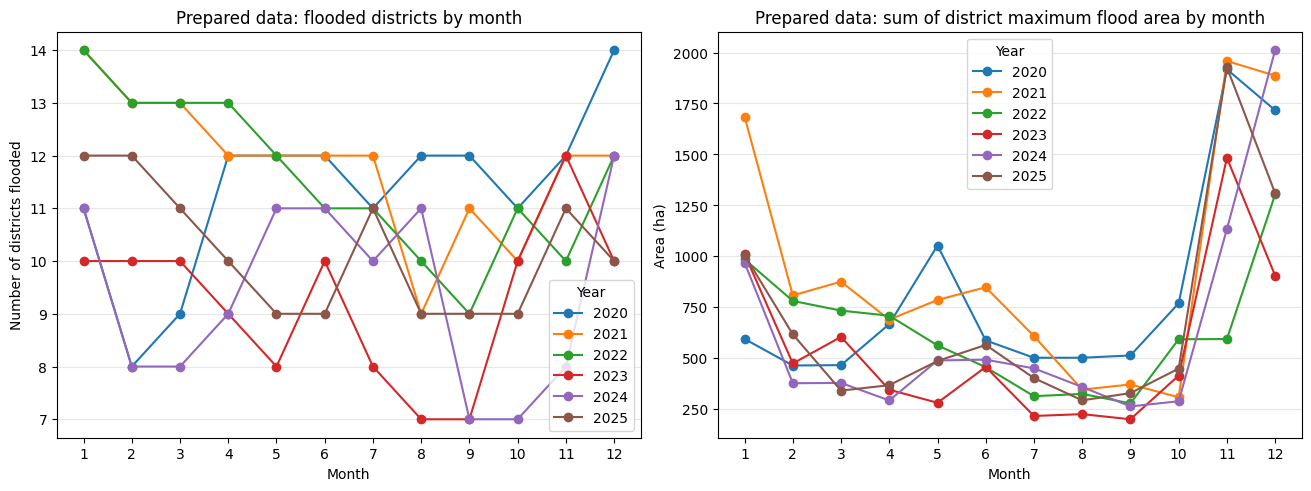

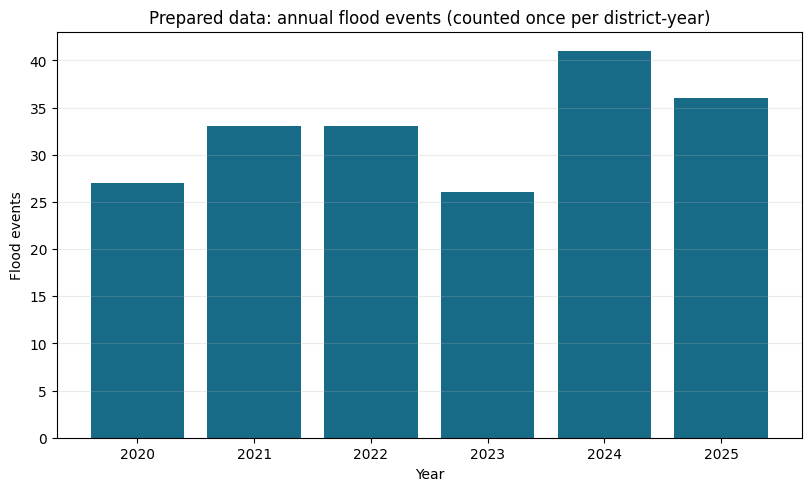

,year,flooded_districts,flood_events
0,2020,14,27
1,2021,10,33
2,2022,8,33
3,2023,9,26
4,2024,13,41
5,2025,8,36


In [6]:
prepared_monthly = data_prep.groupby(['year', 'month'], as_index=False).agg(
    flooded_districts=('flooded', 'sum'),
    max_flood_area_sum_ha=('max_flood_ha', 'sum'),
    flood_events=('flood_events_month', 'sum'),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for year in years:
    subset = prepared_monthly.loc[prepared_monthly['year'] == year]
    axes[0].plot(subset['month'], subset['flooded_districts'], marker='o', label=str(year))
    axes[1].plot(subset['month'], subset['max_flood_area_sum_ha'], marker='o', label=str(year))
axes[0].set(title='Prepared data: flooded districts by month', xlabel='Month', ylabel='Number of districts flooded', xticks=range(1, 13))
axes[1].set(title='Prepared data: sum of district maximum flood area by month', xlabel='Month', ylabel='Area (ha)', xticks=range(1, 13))
for ax in axes:
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)

annual_district = data_prep[['amphoe', 'year', 'flood_events_year']].drop_duplicates(['amphoe', 'year'])
annual = annual_district.groupby('year', as_index=False).agg(
    flooded_districts=('flood_events_year', lambda values: int((values > 0).sum())),
    flood_events=('flood_events_year', 'sum'),
)
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
ax.bar(annual['year'].astype(str), annual['flood_events'], color='#176B87')
ax.set(title='Prepared data: annual flood events (counted once per district-year)', xlabel='Year', ylabel='Flood events')
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)
display(annual)

## 6. Save CSV

บันทึก `data_prep` หลัง Clean และ Data Prep ลงใน `clean_data_set/` โดยแยกขั้นตอน Save เป็นเซลล์สุดท้าย

In [7]:
output_dir = root / 'clean_data_set'
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / 'NST_amphoe_monthly_flood_2020_2025_clean.csv'
data_prep.to_csv(csv_path, index=False, encoding='utf-8-sig', float_format='%.6f', date_format='%Y-%m-%d')
print(f'บันทึก CSV แล้ว: {csv_path}')
print(f'{len(data_prep)} แถว | {data_prep["amphoe"].nunique()} อำเภอ | ปี {years}')

บันทึก CSV แล้ว: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\clean_data_set\NST_amphoe_monthly_flood_2020_2025_clean.csv
1296 แถว | 18 อำเภอ | ปี [2020, 2021, 2022, 2023, 2024, 2025]
